**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
- [`sc-type-py`](https://github.com/kris-nader/sc-type-py) – Saba's suggestion!

In [1]:
import scez
import scanpy as sc
import anndata as ad

import matplotlib.pyplot as plt
from upsetplot import from_contents, UpSet

from utils import *

scanpy==1.9.6 anndata==0.8.0 umap==0.5.7 numpy==1.26.4 scipy==1.15.0 pandas==2.2.3 scikit-learn==1.2.2 statsmodels==0.14.4 igraph==0.11.5 pynndescent==0.5.13


## Load data 
~`adata` -> `scvi` denoised and then clustered~

In [2]:
# results_file = 'preprocessing/adata-denoised-clustered-v3.h5ad.gz'
results_file = 'preprocessing/adata-cleaned.h5ad.gz'

adata = sc.read_h5ad(results_file)

TODO: move this before clustering :)

In [3]:
adata = adata[~adata.obs.cond.str.contains('female')].copy()

In [4]:
adata

AnnData object with n_obs × n_vars = 23674 × 12359
    obs: 'batch', 'cond', 'group', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_cleaned'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'ambient_profile_Gene Expression', 'group_colors', 'hvg', 'leiden', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p_norm', 'raw_counts', 'scaled', 'scar_denoised_counts'
    obsp: 'connectivities', 'distances'

In [5]:
# Randomly order cells by making a random index and subsetting AnnData based on it
# Set a random seed to ensure that the cell ordering will be reproducible
np.random.seed(0)
random_indices = np.random.permutation(list(range(adata.shape[0])))

In [6]:
# del adata.raw, adata.var, adata.uns, adata.varm, adata.obsp

# for col in adata.obs.columns[adata.obs.columns.str.startswith('_')]: 
#     del adata.obs[col]

In [7]:
# for col in adata.obs.filter(like='label').columns:
#     del adata.obs[col]

In [8]:
# adata.var_names_make_unique()

In [9]:
adata

AnnData object with n_obs × n_vars = 23674 × 12359
    obs: 'batch', 'cond', 'group', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_cleaned'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'ambient_profile_Gene Expression', 'group_colors', 'hvg', 'leiden', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p_norm', 'raw_counts', 'scaled', 'scar_denoised_counts'
    obsp: 'connectivities', 'distances'

In [10]:
adata.obs.groupby('batch').size()

batch
MDMA_acute_male_1    3652
MDMA_acute_male_2    3305
MDMA_acute_male_3    1899
MDMA_male_1           311
MDMA_male_2           305
MDMA_male_3           700
Meth_male_1          1866
Meth_male_2           892
Meth_male_3           487
Saline_male_1         358
Saline_male_2        1659
Saline_male_3        8240
dtype: int64

___

/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


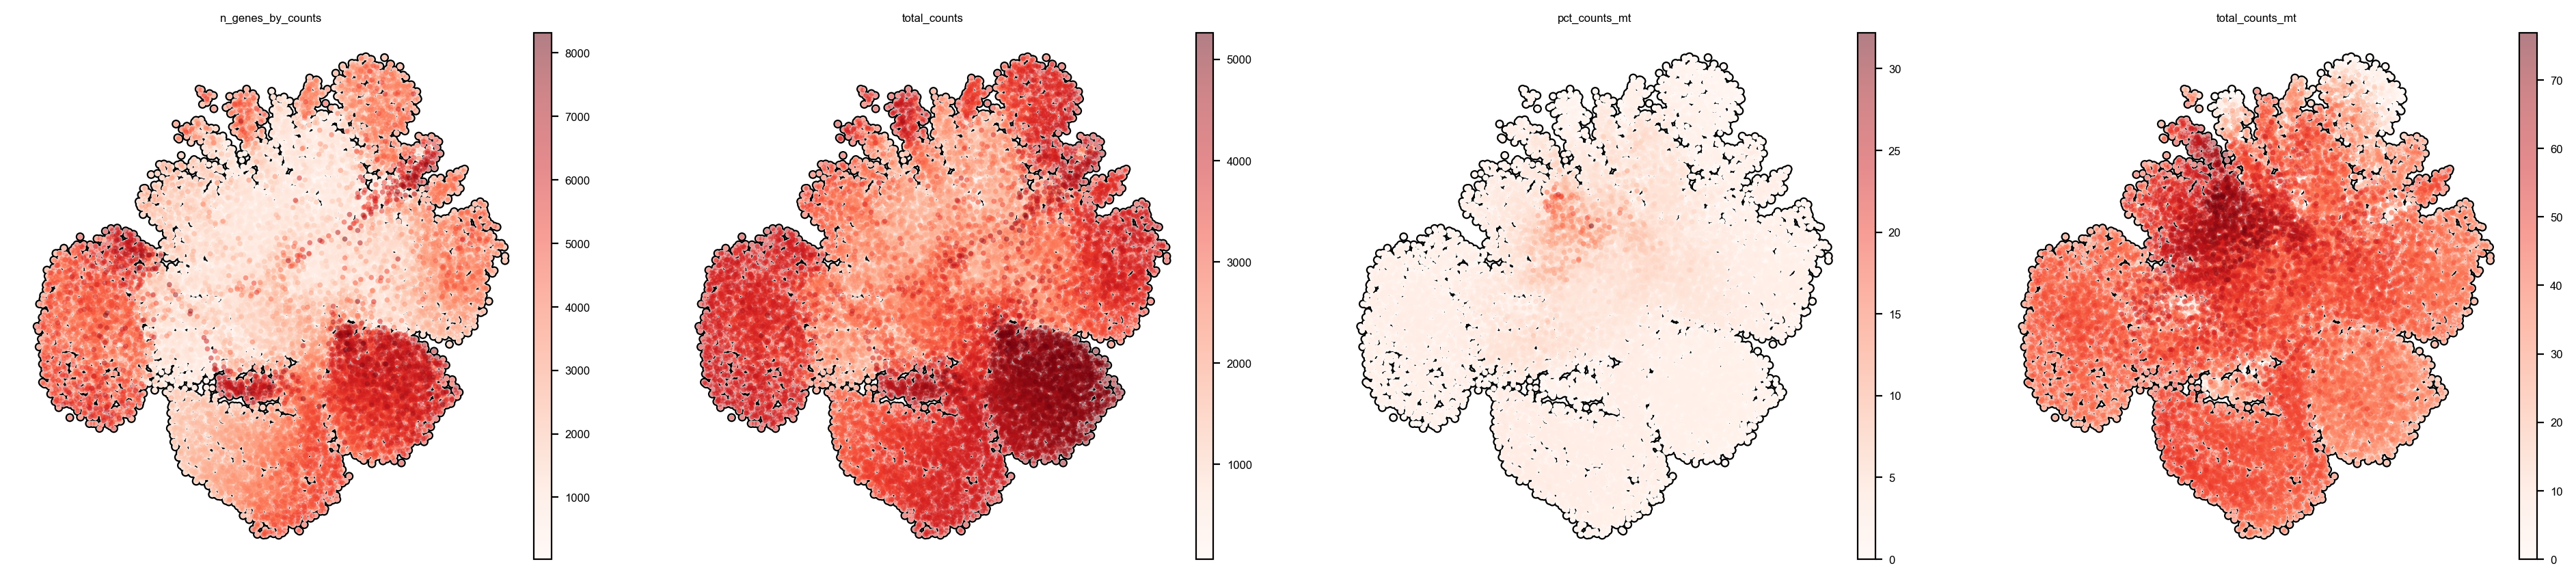

In [11]:
sc.pl.umap(adata[random_indices], color=['n_genes_by_counts', 
                        'total_counts', 
                        'pct_counts_mt',
                        'total_counts_mt'],
               color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

### sc-type

Suggested by Saba!

https://github.com/kris-nader/sc-type-py/

In [12]:
# import urllib.request

# # Fetch the script from the URL
# url = "https://raw.githubusercontent.com/kris-nader/sc-type-py/main/sctype_py.py"
# response = urllib.request.urlopen(url)
# script = response.read().decode()

# # Execute the script
# exec(script)

## marker genes for neuronal/non-neuronal cells

In [12]:
cell_types = {
    "non-neuron":[
        "Endothelial",
        "Oligodentrocyte",
        "Microglia",
        "astrocytes",
    ],
    "neuron":[
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN",
        "D1H",
        "ICj"
    ]
}

In [23]:
# https://chatgpt.com/share/677c785b-2818-800c-931e-64334f9e4e18
# KeyError: "Could not find keys '['Htr4','Casz1', 'Cbln1', 'Chat', 'Drd2', 'Mbpa', 'Pdyn']'

na_markers = {
    "Neurons": ["Snap25","Bcl11b", "Pde10a"],  # General MSN markers
    "D1_MSN": ["Drd1", "Sema5b","Ebf1","Ppm1e","Grm8","Tac1"],  # D1-type MSNs (direct pathway)
    "D2_MSN": ["Adora2a","Stk32a","Scube1","Penk"],  # D2-type MSNs (indirect pathway)
    # "Striosomal": , "Grm8"],  # Striosomal MSN-specific markers
    "Non_MSN_Neurons": ["Sst", "Pvalb"],  # Non-MSN neuronal subtypes
    "Interneurons":['Resp18',"Pvalb", "Calb2"],
    # "Matrix": ["Cbln1", "Ebf1"],  # Matrix MSN-specific markers
    "Astrocytes": ["Aqp4"],  # Astrocyte markers
    "Microglia": ["C1qa", "C1qb"],  # Microglia markers
    "Oligodendrocytes": ["Mog"],  # Oligodendrocyte markers
    "Endothelial_Cells": ["Flt1", "Pecam1"],  # Endothelial cell markers
}

In [24]:
# saba_s_genes
#     "Tac1",
#     "Pcp4",
#     "Ly6h",
#     "Syt5",
#     "Caly",
#     "Snhg11",
#     "Ctxn1",
#     "Rtn1",
#     "Bex2",
#     "Meg3"

#     "Endothelial": ["Cldn5","Flt1","Id1","Ptprb"],
#     "Smooth Muscle":['Cald1',"Rgs5"],
#     "Oligodentrocyte":["Mog",'Opalin'], #, "Olig1"],
#     "Microglia":['C1qb','C1qa'], #"Cx3cr1"],
#     "astrocytes":[
#         # 'Aldoc',
#         'Slc1a2',
#         # 'Slc1a3','Gja1'
#     ], # "Aqp4"],
#     "Neuron":[
#         'Snap25','Sox11',
#         "Bcl2"
#         # "Gt(ROSA)26Sor"
#     ],
#     # "GABAergic":["Gad1"],
#     # "glutamatergic":[
#     #     "Grin3a",
#     #     "Lrrtm2",
#     #     "Slc1a1",
#     #     "Slc1a2",
#     #     "Gria1",
#     #     # "Gria2",
#     #     # "Grin1",
#     #     # "Slc6a13",
#     #     # "Slc7a11",
#     #     # "Slc17a7",
#     #     # "Slc17a6",
#     # ],
#     "D1/2 MSN":[
#         "Arpp21",
#         # "Ppp3ca",
#         'Tac1',
#         # "Pdyn",
#         "Sfxn1",
#         "Pcdh8",
#         "Adarb2",
#         # "Tshz1",
#         "Ptpn5",
#         "Snca",
#     ],
    
#     "OPC":[
#         "Pdgfra",
#     ],
    
#     # "D1H":[
#         # "Nxph4",
#         # "Tac2"
#     # ],
#     # "ICj":[
#         # "Crtac1",
#         # "Rreb1"],
#     # "patch marker":["Sema5b"],
#     # "ventral striatum marker":["Crym"],
#     # "medial Shell":[
#     #     "Stard5",
#     #     "Stra6"]
# #     "Interneurons":[
# #         'Resp18', # as initial marker
# #         # "Chat", 
# #         "Pvalb", 
# #         # "Trh", 
# #         "Calb2", 
# #         # "Pthlh", 
# #         "Afap1", "Hhip", #"Crhbp" # - sub clustering: 
# #         # - some are overlapping and labeled by combination of multiple or as high or low e.g. Sst+/Hhip+, Sst+/Hhip−
# #     ]
# }    

In [25]:
# not_neuron_genes = dict([(k,v) for k,v in marker_genes.items() if k in cell_types['non-neuron']])

In [26]:
# neuron_genes = dict([(k,v) for k,v in marker_genes.items() if k in cell_types['neuron']])

## Dot plots

categories: 0, 1, 2, etc.
var_group_labels: Neurons, D1_MSN, D2_MSN, etc.


/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


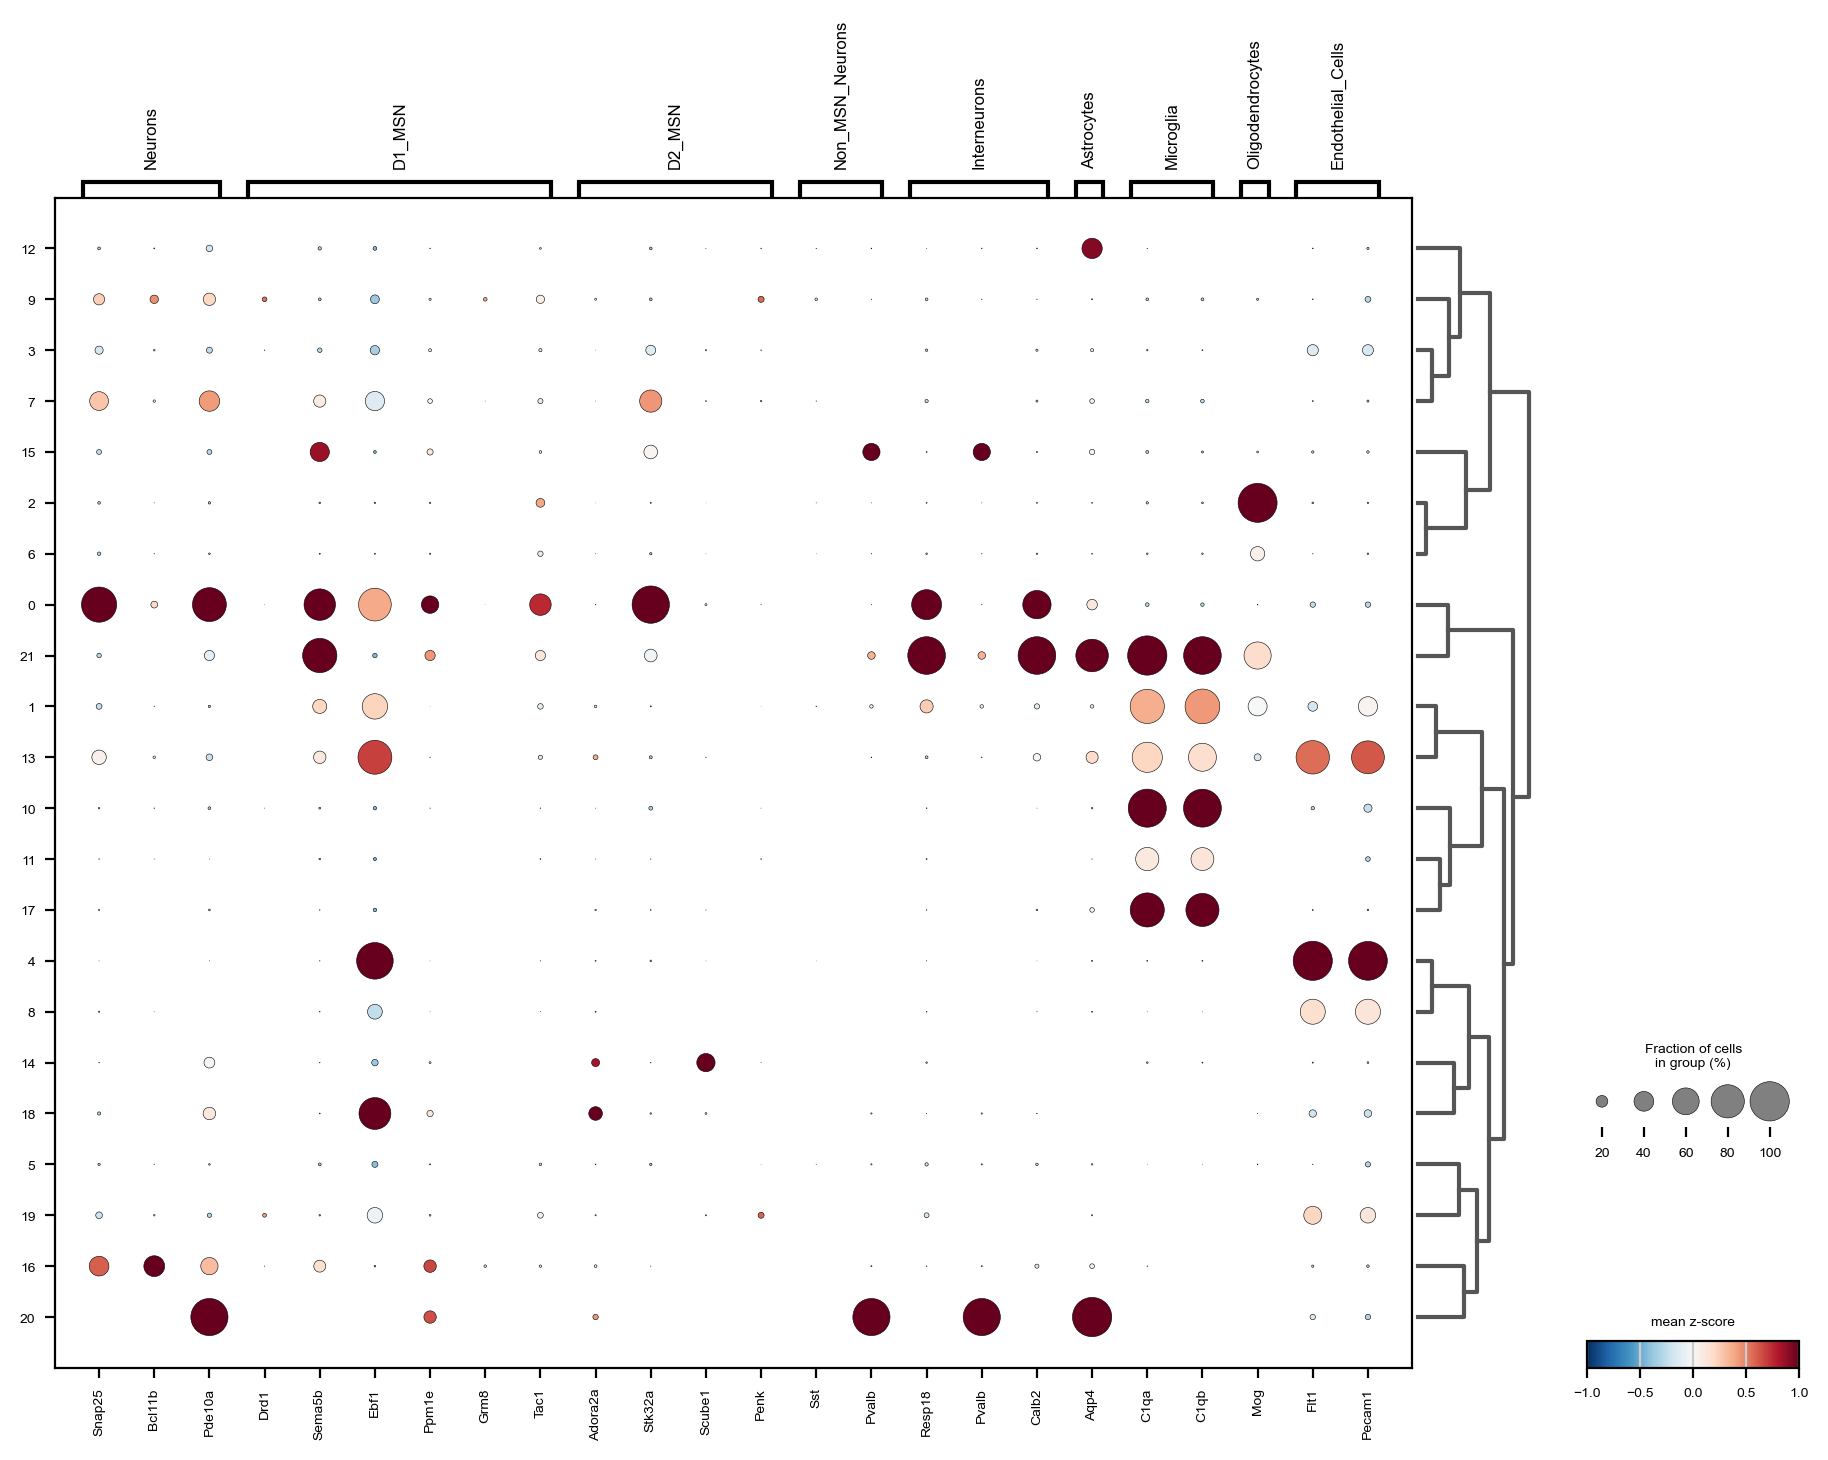

In [27]:
ax = sc.pl.dotplot(
    adata,
    # saba_s_genes,
    # marker_genes, 
    na_markers,
    groupby=['leiden_cleaned'], #,'leiden_scVI'
    swap_axes=False, 
    dendrogram=True,
    
    # colorbar_title='log1p(CP10k)', 
    # layer='log1p_norm', 
    # vmin=0, vmax=4, 
    # cmap='Reds'

    layer='scaled', 
    vmin=-1, vmax=1, 
    cmap='RdBu_r',
    colorbar_title='mean z-score', 

    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

____
#### Annotate clusters:

In [28]:
leiden_list = []

for l in adata.obs.leiden_cleaned:
    if int(l) in [10,11,17]: leiden_list.append('Microglia')
    elif int(l) in [12]: leiden_list.append('Astrocytes')
    elif int(l) in [1,4,8,13]: leiden_list.append('Endothelial')
    # elif int(l) in [18]: leiden_list.append('Smooth Muscle')
    # elif int(l) in [14]: leiden_list.append('OPC')
    elif int(l) in [2,6]: leiden_list.append('Oligodendrocytes')
    # elif int(l) in [0,1,7,9,14,20]: leiden_list.append('D1/2 Neuron')
    elif int(l) in [
        20,0,7,16,9, ## Mostly Snap25+, Pde10a+, and Bcl11b+
        14,18,     ## Only expressing D1/D2 markers
        # 13,21    ## Also expressing markers of other cell types!
    ]:leiden_list.append('Neuron')
    else: leiden_list.append(l)

adata.obs['label'] = pd.Categorical(leiden_list)

In [29]:
sc.tl.dendrogram(adata,['label']) 
sc.tl.dendrogram(adata,['label','leiden_cleaned']) 

categories: 15, 19, 21, etc.
var_group_labels: Neurons, D1_MSN, D2_MSN, etc.


/data_gilbert/home/aarab/miniconda3/envs/scez/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


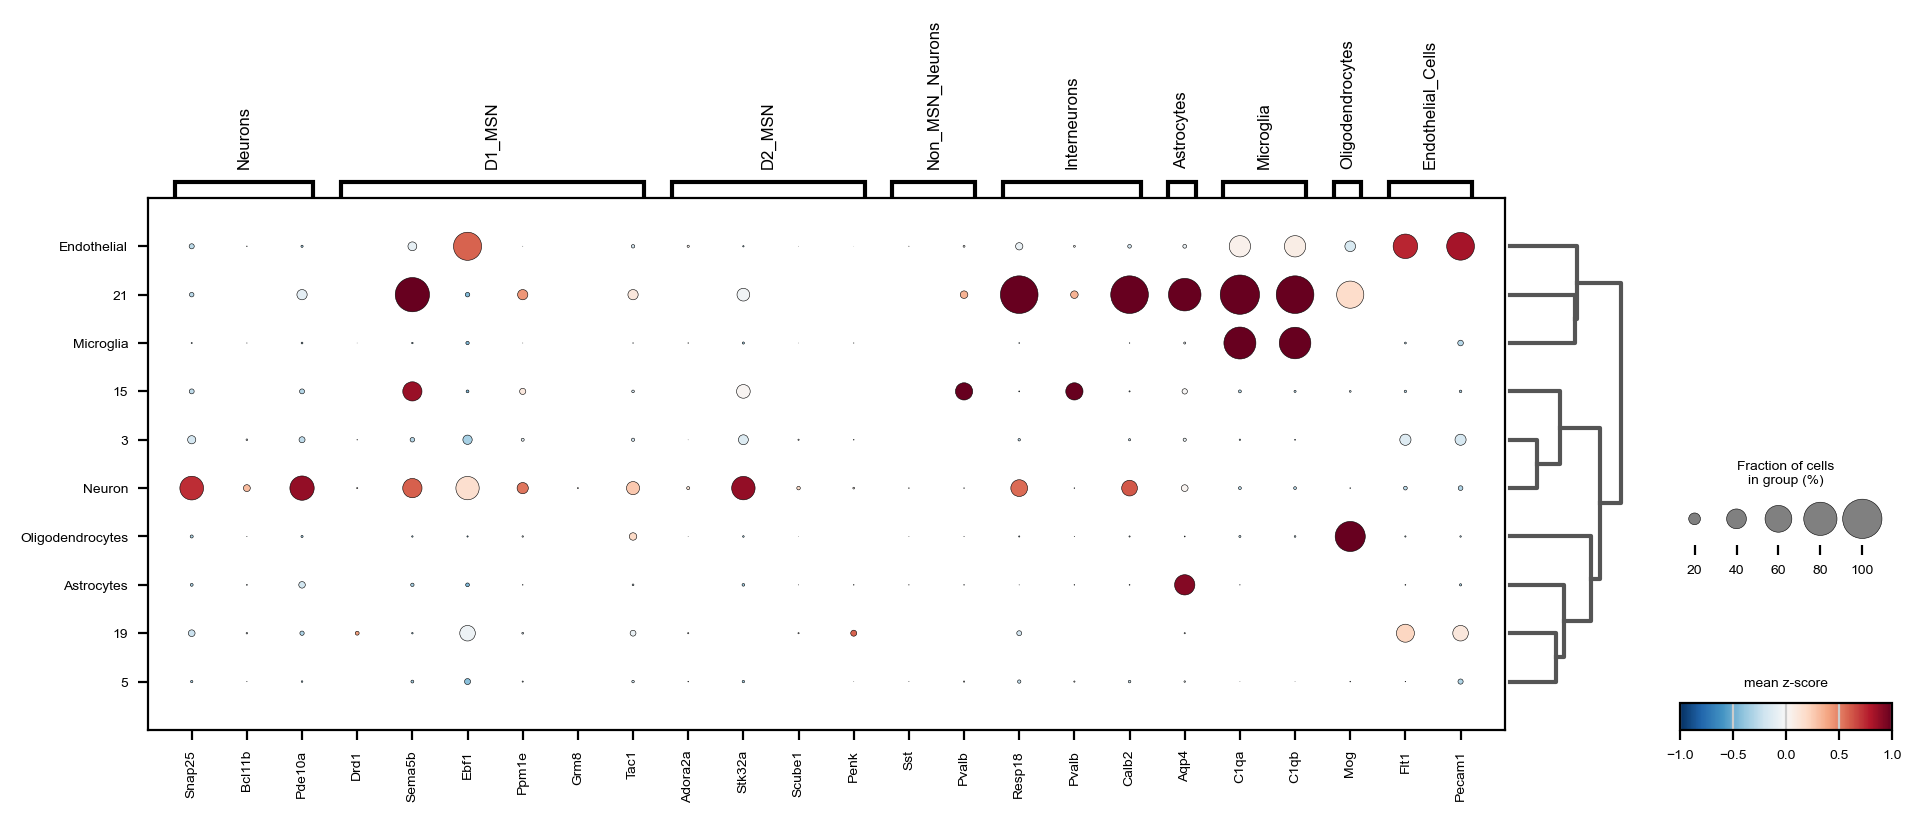

In [30]:
ax = sc.pl.dotplot(
    adata,
    # marker_genes, 
    # not_neuron_genes, 
    na_markers,
    groupby=['label'], 
    swap_axes=False, dendrogram=True,

    # colorbar_title='log1p(CP10k)', 
    # layer='log1p_norm', 
    # vmin=0, vmax=4, 
    # cmap='Reds'

    layer='scaled', 
    vmin=-1, vmax=1, 
    cmap='RdBu_r',
    colorbar_title='mean z-score', 

    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

In [32]:
# sc.pl.umap(
#     adata[random_indices],
#     # adata[adata.obs.leiden_cleaned.isin([str(i) for i in[
#     #     0,1,2,3,4,#5,6,7,11,12,14,15,17,19,20,21,22
#     # ]])],
#     layer='log1p_norm', 
#     color=['leiden_cleaned','label','cond',
#            # 'Mog','Sorl1','Tshz1','Cldn5','C1qa','C1qb'
#           ],
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=30,
#     # legend_loc='on data',
#     add_outline=0.1
# )

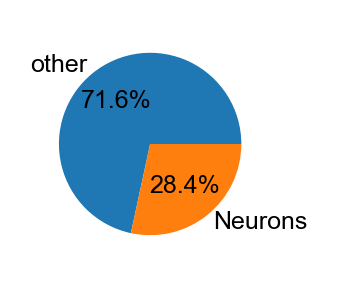

In [33]:
d = pd.DataFrame(adata.obs['label'].str.contains('Neuron')).groupby('label').size()

fig = plt.figure(figsize =(1, 1),dpi=150)
plt.pie(d.values,labels=['other','Neurons'],autopct='%1.1f%%')
# show plot
plt.show()

___
<!-- ### Label tdT+/-
Divide cells into `Gt(ROSA)26Sor+` and `'Gt(ROSA)26Sor-` populations -->

In [34]:
# tdT_gene = "Gt(ROSA)26Sor"

In [35]:
# ax = scez.utils.add_marker_feature(adata,marker='Bcl11b',marker_name='Bcl11b label',clusters_name='leiden_cleaned')

# # plt.savefig('celltyping/percent_in_clust_denoised_TdT.pdf')
# # # show plot
# plt.show()

In [36]:
# ax = scez.utils.add_marker_feature(adata,marker='Snap25',marker_name='Snap25 label',clusters_name='leiden_cleaned')

# # plt.savefig('celltyping/percent_in_clust_denoised_TdT.pdf')
# # # show plot
# plt.show()

In [37]:
# ax = scez.utils.add_marker_feature(adata,marker='Pde10a',marker_name='Pde10a label',clusters_name='leiden_cleaned')

# # plt.savefig('celltyping/percent_in_clust_denoised_TdT.pdf')
# # # show plot
# plt.show()

## Split dataset

In [49]:
adata_neuron = adata[adata.obs.label == 'Neuron'].copy()

In [50]:
adata_non_neuron = adata[adata.obs.label != 'Neuron'].copy()

# Neurons

In [51]:
# Randomly order cells by making a random index and subsetting AnnData based on it
# Set a random seed to ensure that the cell ordering will be reproducible
np.random.seed(0)
random_indices_neuron = np.random.permutation(list(range(adata_neuron.shape[0])))

#### Scale

In [52]:
adata_neuron.layers['scaled'] = sc.pp.scale(adata_neuron, copy=True).X

In [53]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

#### sub-clustering

In [54]:
adata_neuron

AnnData object with n_obs × n_vars = 6720 × 12359
    obs: 'batch', 'cond', 'group', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_cleaned', 'label'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'ambient_profile_Gene Expression', 'group_colors', 'hvg', 'leiden', 'neighbors', 'pca', 'umap', 'dendrogram_leiden_cleaned', 'dendrogram_label', 'dendrogram_label_leiden_cleaned'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p_norm', 'raw_counts', 'scaled', 'scar_denoised_counts'
    obsp: 'connectivities', 'distances'

In [55]:
sc.pp.neighbors(adata_neuron)
sc.tl.umap(adata_neuron, min_dist=0.3)
sc.tl.leiden(adata_neuron, key_added="leiden_neuron", resolution=0.5)

___

In [56]:
# sc.pl.umap(
#     adata_neuron[random_indices_neuron], 
#     # color='leiden_neuron'
#     # layer='log1p_norm',
#     color=['leiden_cleaned','leiden_neuron','cond'] + na_markers['Neurons'] + na_markers['D1_MSN'],
#     frameon=False,
#     # alpha=0.5,
#     size=20,

#     layer='log1p_norm', 
#     vmin=0, vmax=4, 
#     cmap='Reds',

#     # legend_loc='on data',
#     # add_outline=0.0001
    
#     save = 'D1_MSN'
# )

#### save small data for browser view
https://www.kanaverse.org/kana/

In [ ]:
adata_neuron_small = adata_neuron.copy()

# adata_neuron_small = adata_neuron_small[:,adata_neuron_small.var.highly_variable].copy()

adata_neuron_small.var = adata_neuron_small.var.reset_index().rename(
    columns={'index':'gene_names'}).set_index('gene_ids')

In [ ]:
del adata_neuron_small.layers

del adata_neuron_small.uns['ambient_profile_Gene Expression']
del adata_neuron_small.uns['group_colors']

for col in ["n_counts","n_genes_by_counts","total_counts","total_counts_mt","pct_counts_mt"]:
    del adata_neuron_small.obs[col]

for col in adata_neuron_small.var.columns:
    if col not in ["gene_names","total_counts",'highly_variable']:
        del adata_neuron_small.var[col]

In [ ]:
del adata_neuron_small.uns['dendrogram_label_leiden_cleaned']
del adata_neuron_small.uns['dendrogram_leiden_cleaned']
del adata_neuron_small.uns['dendrogram_label']

In [ ]:
adata_neuron_small

In [ ]:
results_file = 'celltyping/adata_neuron.small.h5ad'

adata_neuron_small.write(results_file)

In [ ]:
!ls -s --block-size=M celltyping/adata_neuron*

#### save top genes per cluster

In [61]:
# sc.tl.rank_genes_groups(
#     adata_neuron, 'leiden_neuron', method='wilcoxon'
# )

In [62]:
# sc.pl.rank_genes_groups(adata_neuron)

In [60]:
# sc.pl.rank_genes_groups_dotplot(adata_neuron)

In [ ]:
# neuron_ranked_clusters_full = scez.utils.rank_genes_to_df(
#     adata_neuron,
#     n = 200
# )

In [ ]:
# neuron_ranked_clusters_full.add_prefix('neuron_').to_csv('celltyping/ranked_neuron_clusters_full.csv')

#### Explore neurons

In [ ]:
sc.tl.dendrogram(adata_neuron,'leiden_neuron') 

In [ ]:
ax = sc.pl.dotplot(
    adata_neuron,
    neuron_genes, 
    # marker_genes, 
    groupby=['leiden_neuron'], #,'leiden_scVI'
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

In [ ]:
# leiden_list = []
# for l in adata_neuron.obs.leiden_non_neuron:
#     if int(l) in [4]: leiden_list.append('Microglia')
#     elif int(l) in [3]: leiden_list.append('Astrocytes')
#     elif int(l) in [1]: leiden_list.append('Endothelial')
#     elif int(l) in [0]: leiden_list.append('Oligodendrocytes')
#     else: leiden_list.append(l)

# adata_neuron.obs['label'] = pd.Categorical(leiden_list)

In [ ]:
# sc.tl.dendrogram(adata_neuron,'label') 

In [ ]:
# ax = sc.pl.dotplot(
#     adata_neuron,
#     not_neuron_genes, 
#     groupby=['label','leiden_scVI'], 
#     swap_axes=False, dendrogram=True,
#     colorbar_title='mean z-score', 
#     layer='scaled', 
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     # save = 'Snap25_neg'
# )

# # !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

In [ ]:
# sc.pl.violin(adata_neuron, ['n_genes_by_counts', 
#                         'total_counts', 
#                         'pct_counts_mt',
#                         'total_counts_mt'],
#              jitter=0.05, multi_panel=True)

In [ ]:
sc.pl.umap(
    adata_neuron,
    color=[
        'leiden_scVI',
        'leiden_neuron',
        'label',
        # 'mean_counts',
        "Foxp1",
        "Kcnc1", "Acan", "Pvalb", "Junb",
        "Snap25",'Sox11',
        "Mog","Ptprb",
        'group',
    ],
    # vmax=2,
    # vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

### Save to file

Here, we need to think more about how to find subclusters!

In [63]:
# results_file = 'celltyping/adata_neuron-clustered-v3.h5ad.gz'
results_file = 'celltyping/adata_neuron-clustered-v4.h5ad.gz'

adata_neuron.write_h5ad(results_file)

# Non-Neurons

In [ ]:
adata_non_neuron

#### Scale

In [ ]:
adata_non_neuron.layers['scaled'] = sc.pp.scale(adata_non_neuron, copy=True).X

In [ ]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_non_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [ ]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_non_neuron, use_rep="X_scVI")
sc.tl.umap(adata_non_neuron, min_dist=0.3)
# neighbors were already computed using scVI
sc.tl.leiden(adata_non_neuron, key_added="leiden_non_neuron", resolution=0.1)

In [ ]:
sc.tl.dendrogram(adata_non_neuron,'leiden_non_neuron') 

In [ ]:
sc.pl.umap(
    adata_non_neuron, 
    color=['leiden_non_neuron'] + 
    [gene for _,genes in not_neuron_genes.items() for gene in genes],
    vmax=1,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    layer='scaled',
)

In [ ]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['leiden_non_neuron'], #,'leiden_scVI'
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

In [ ]:
leiden_list = []
for l in adata_non_neuron.obs.leiden_non_neuron:
    if int(l) in [4]: leiden_list.append('Microglia')
    elif int(l) in [3]: leiden_list.append('Astrocytes')
    elif int(l) in [1]: leiden_list.append('Endothelial')
    elif int(l) in [0]: leiden_list.append('Oligodendrocytes')
    else: leiden_list.append(l)

adata_non_neuron.obs['label'] = pd.Categorical(leiden_list)

In [ ]:
sc.tl.dendrogram(adata_non_neuron,'label') 

In [ ]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['label','leiden_scVI'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

In [ ]:
sc.pl.umap(
    adata_non_neuron,
    color=[
        'leiden_scVI',
        'leiden_non_neuron',
        'label',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        'group',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

##### 
save :)

In [ ]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron.write_h5ad(results_file)

# All data

In [ ]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron = ad.read_h5ad(results_file)

In [ ]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = ad.read_h5ad(results_file)

In [ ]:
adata = ad.concat([adata_neuron, adata_non_neuron])

In [ ]:
adata.obs['final label'] = ''

adata.obs.loc[adata_neuron.obs_names,'final label'] = 'neuron'#list(adata_neuron.obs.leiden_neuron)
adata.obs.loc[adata_non_neuron.obs_names,'final label'] = list(adata_non_neuron.obs.label)

adata.obs['final label'] = pd.Categorical(list(adata.obs['final label']))

In [ ]:
adata

In [ ]:
adata.obs.loc[adata_neuron.obs_names,'leiden_neuron'] = list(adata_neuron.obs.leiden_neuron)
adata.obs['leiden_neuron'] = pd.Categorical(list(adata.obs['leiden_neuron']))

#### scale

In [ ]:
adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

In [ ]:
sc.pp.pca(adata,n_comps=30)

In [ ]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI",n_neighbors=30)
sc.tl.umap(adata, min_dist=0.1)

In [ ]:
sc.pl.umap(
    adata,
    color=[
        # 'group',
        'leiden_scVI',
        # 'leiden_neuron',
        "TdT label",
        # 'Snap25 label',
        'final label',
        # "Sox11",'Snap25',
    ],
    vmax=.1,vmin=-.1,
    layer='scaled',
    color_map="Reds",
    frameon=False,
    # alpha=0.1,
    size=1,
    # legend_loc='on data',
    # add_outline=0.01,
    save = '_20230313'
)

!mv -v figures/umap_20230313.pdf celltyping/

### 

> - Groups and cell counts per group (would you please get me updated cell counts for each group?)

> - Amount that are tdT positive (less than expected – would you please generate a new UMAP highlighting tdT expression?)

In [ ]:
pd.DataFrame(
    adata.obs.groupby(['batch','final label']).size()
).rename(columns={0:'# of cells'}).to_excel('num_cell_per_group.xlsx')

### Save final `adata`

In [ ]:
adata_final = adata.copy()

In [ ]:
del adata_final.obsm, adata_final.raw, adata_final.var, adata_final.uns, adata_final.varm, adata_final.obsp

In [ ]:
for col in adata_final.obs.filter(like=' label').columns:
    del adata_final.obs[col]

In [ ]:
results_file = 'preprocessing/adata-annotated.h5ad.gz'

adata_final.write_h5ad(results_file)

In [ ]:
adata_final.to_df('counts').T.to_csv('preprocessing/adata-annotated-counts.csv.gz',compression='gzip')

In [ ]:
adata_final.obs.to_csv('preprocessing/adata-annotated-meta.csv.gz',compression='gzip')

In [ ]:
ls -lh preprocessing/adata-annotated*

# 

In [38]:
%load_ext watermark

In [39]:
%watermark
%watermark --iversions

Last updated: 2025-01-07T03:01:25.337290-08:00

Python implementation: CPython
Python version       : 3.11.11
IPython version      : 8.31.0

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 3.10.0-957.27.2.el7.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 64
Architecture: 64bit

upsetplot : 0.9.0
scanpy    : 1.9.6
numpy     : 1.26.4
pandas    : 2.2.3
matplotlib: 3.9.2
scez      : 0.1.2
anndata   : 0.8.0



___